# French Word Embeddings: Training and Similarity Evaluation

This experiment uses the QUAERO FrenchMed medical corpus and QUAERO FrenchPress news corpus. It trains Word2Vec CBOW, Word2Vec Skip-gram, and FastText CBOW models with vector size 100 and `min_count=1`.

In [7]:
%pip install -q gensim fasttext


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
from pathlib import Path
try:
    import fasttext
except ImportError:
    fasttext = None
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from gensim.models import FastText, Word2Vec

ROOT = Path.cwd()
DATA_PATHS = {
    'Medical corpus': ROOT / 'TP_ISD2020/QUAERO_FrenchMed/QUAERO_FrenchMed_traindev.ospl',
    'Press corpus': ROOT / 'TP_ISD2020/QUAERO_FrenchPress/QUAERO_FrenchPress_traindev.ospl',
}
MODEL_DIR = ROOT / 'models_word_vectors'
FIGURE_DIR = ROOT / 'word_embedding_figures'
MODEL_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

DIM = 100
MIN_COUNT = 1
EPOCHS = 10
WINDOW = 5
TARGET_WORDS = ['patient', 'traitement', 'maladie', 'solution', 'jaune']

def read_corpus(path):
    return [line.strip().split() for line in path.read_text(encoding='utf-8').splitlines() if line.strip()]

sentences = {name: read_corpus(path) for name, path in DATA_PATHS.items()}
stats = []
for name, corpus in sentences.items():
    tokens = [token for sentence in corpus for token in sentence]
    stats.append({
        'Corpus': name,
        'Sentences': len(corpus),
        'Tokens': len(tokens),
        'Vocabulary size': len(set(tokens)),
    })
pd.DataFrame(stats)

,Corpus,Sentences,Tokens,Vocabulary size
0,Medical corpus,3021,51896,9104
1,Press corpus,38548,1251561,39654


## Train and Save Models

In [9]:
trained_models = {}
model_paths = {}

for corpus_name, corpus in sentences.items():
    corpus_key = 'med' if corpus_name == 'Medical corpus' else 'press'
    for model_name, sg in [('Word2Vec-CBOW', 0), ('Word2Vec-SkipGram', 1)]:
        model = Word2Vec(
            sentences=corpus,
            vector_size=DIM,
            window=WINDOW,
            min_count=MIN_COUNT,
            sg=sg,
            workers=4,
            epochs=EPOCHS,
            seed=42,
        )
        model_path = MODEL_DIR / f'{corpus_key}_{model_name.lower().replace("-", "_")}.model'
        model.save(str(model_path))
        trained_models[(corpus_name, model_name)] = model
        model_paths[(corpus_name, model_name)] = model_path

    if fasttext is not None:
        fasttext_model = fasttext.train_unsupervised(
            input=str(DATA_PATHS[corpus_name]),
            model='cbow',
            dim=DIM,
            ws=WINDOW,
            epoch=EPOCHS,
            minCount=MIN_COUNT,
            minn=3,
            maxn=6,
            bucket=100000,
            thread=4,
            verbose=0,
        )
        fasttext_path = MODEL_DIR / f'{corpus_key}_fasttext_cbow.bin'
        fasttext_model.save_model(str(fasttext_path))
    else:
        fasttext_model = FastText(
            sentences=corpus,
            vector_size=DIM,
            window=WINDOW,
            min_count=MIN_COUNT,
            sg=0,
            min_n=3,
            max_n=6,
            bucket=100000,
            workers=4,
            epochs=EPOCHS,
            seed=42,
        )
        fasttext_path = MODEL_DIR / f'{corpus_key}_fasttext_cbow.model'
        fasttext_model.save(str(fasttext_path))
    trained_models[(corpus_name, 'FastText-CBOW')] = fasttext_model
    model_paths[(corpus_name, 'FastText-CBOW')] = fasttext_path

pd.DataFrame({
    'Corpus': [key[0] for key in trained_models],
    'Model': [key[1] for key in trained_models],
    'Model path': [
        str(model_paths[key])
        for key in trained_models
    ],
})

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


,Corpus,Model,Model path
0,Medical corpus,Word2Vec-CBOW,/Users/luran/Documents/ChatGPT/NLP Today/model...
1,Medical corpus,Word2Vec-SkipGram,/Users/luran/Documents/ChatGPT/NLP Today/model...
2,Medical corpus,FastText-CBOW,/Users/luran/Documents/ChatGPT/NLP Today/model...
3,Press corpus,Word2Vec-CBOW,/Users/luran/Documents/ChatGPT/NLP Today/model...
4,Press corpus,Word2Vec-SkipGram,/Users/luran/Documents/ChatGPT/NLP Today/model...
5,Press corpus,FastText-CBOW,/Users/luran/Documents/ChatGPT/NLP Today/model...


## Top10 Cosine-Similar Neighbors

In [10]:
def get_neighbors(model, word, topn=10):
    if isinstance(model, (Word2Vec, FastText)):
        return model.wv.most_similar(word, topn=topn)
    return [(neighbor, score) for score, neighbor in model.get_nearest_neighbors(word, k=topn)]

results = []
for (corpus_name, model_name), model in trained_models.items():
    vocabulary = set(model.wv.index_to_key) if isinstance(model, (Word2Vec, FastText)) else set(model.words)
    for target in TARGET_WORDS:
        if target not in vocabulary:
            continue
        for rank, (neighbor, similarity) in enumerate(get_neighbors(model, target), start=1):
            results.append({
                'Corpus': corpus_name,
                'Model': model_name,
                'Target': target,
                'Rank': rank,
                'Neighbor': neighbor,
                'Cosine similarity': similarity,
            })

results_df = pd.DataFrame(results)
for corpus_name in DATA_PATHS:
    for model_name in ['Word2Vec-CBOW', 'Word2Vec-SkipGram', 'FastText-CBOW']:
        table = results_df[(results_df['Corpus'] == corpus_name) & (results_df['Model'] == model_name)].copy()
        print(f'{corpus_name} | {model_name}')
        display(table[['Target', 'Rank', 'Neighbor', 'Cosine similarity']].round({'Cosine similarity': 4}).reset_index(drop=True))

Medical corpus | Word2Vec-CBOW


,Target,Rank,Neighbor,Cosine similarity
0,patient,1,Le,0.9991
1,patient,2,cette,0.9988
2,patient,3,qu,0.9988
3,patient,4,Tysabri,0.9986
4,patient,5,ce,0.9984
5,patient,6,nécessaire,0.9982
6,patient,7,pris,0.9982
7,patient,8,Epivir,0.9982
8,patient,9,est,0.9981
9,patient,10,par,0.9981


Medical corpus | Word2Vec-SkipGram


,Target,Rank,Neighbor,Cosine similarity
0,patient,1,carte,0.9786
1,patient,2,tout,0.9753
2,patient,3,cette,0.9730
3,patient,4,prévenir,0.9723
4,patient,5,interrompu,0.9707
5,patient,6,ils,0.9699
6,patient,7,pris,0.9696
7,patient,8,car,0.9694
8,patient,9,prescrit,0.9689
9,patient,10,interrompre,0.9689


Medical corpus | FastText-CBOW


...

,Target,Rank,Neighbor,Cosine similarity
0,patient,1,déferlement,0.7945
1,patient,2,équipé,0.7621
2,patient,3,dévouement,0.7431
3,patient,4,orchestre,0.7422
4,patient,5,effort,0.7320
5,patient,6,lac,0.7299
6,patient,7,rescapé,0.7296
7,patient,8,essai,0.7285
8,patient,9,immigré,0.7276
9,patient,10,garage,0.7251


Press corpus | Word2Vec-SkipGram


,Target,Rank,Neighbor,Cosine similarity
0,patient,1,mollah,0.8767
1,patient,2,coq,0.8690
2,patient,3,idéologie,0.8507
3,patient,4,circonstance,0.8492
4,patient,5,pulsion,0.8489
5,patient,6,truc,0.8489
6,patient,7,ordinateur,0.8476
7,patient,8,complément,0.8460
8,patient,9,brevet,0.8460
9,patient,10,identification,0.8433


Press corpus | FastText-CBOW


,Target,Rank,Neighbor,Cosine similarity
0,patient,1,impatient,0.9679
1,patient,2,patientent,0.9559
2,patient,3,détient,0.9415
3,patient,4,abstient,0.9371
4,patient,5,soutient,0.9369
5,patient,6,tient,0.9347
6,patient,7,obtient,0.9345
7,patient,8,échoient,0.9344
8,patient,9,quotient,0.9303
9,patient,10,initient,0.9268


## Visualization

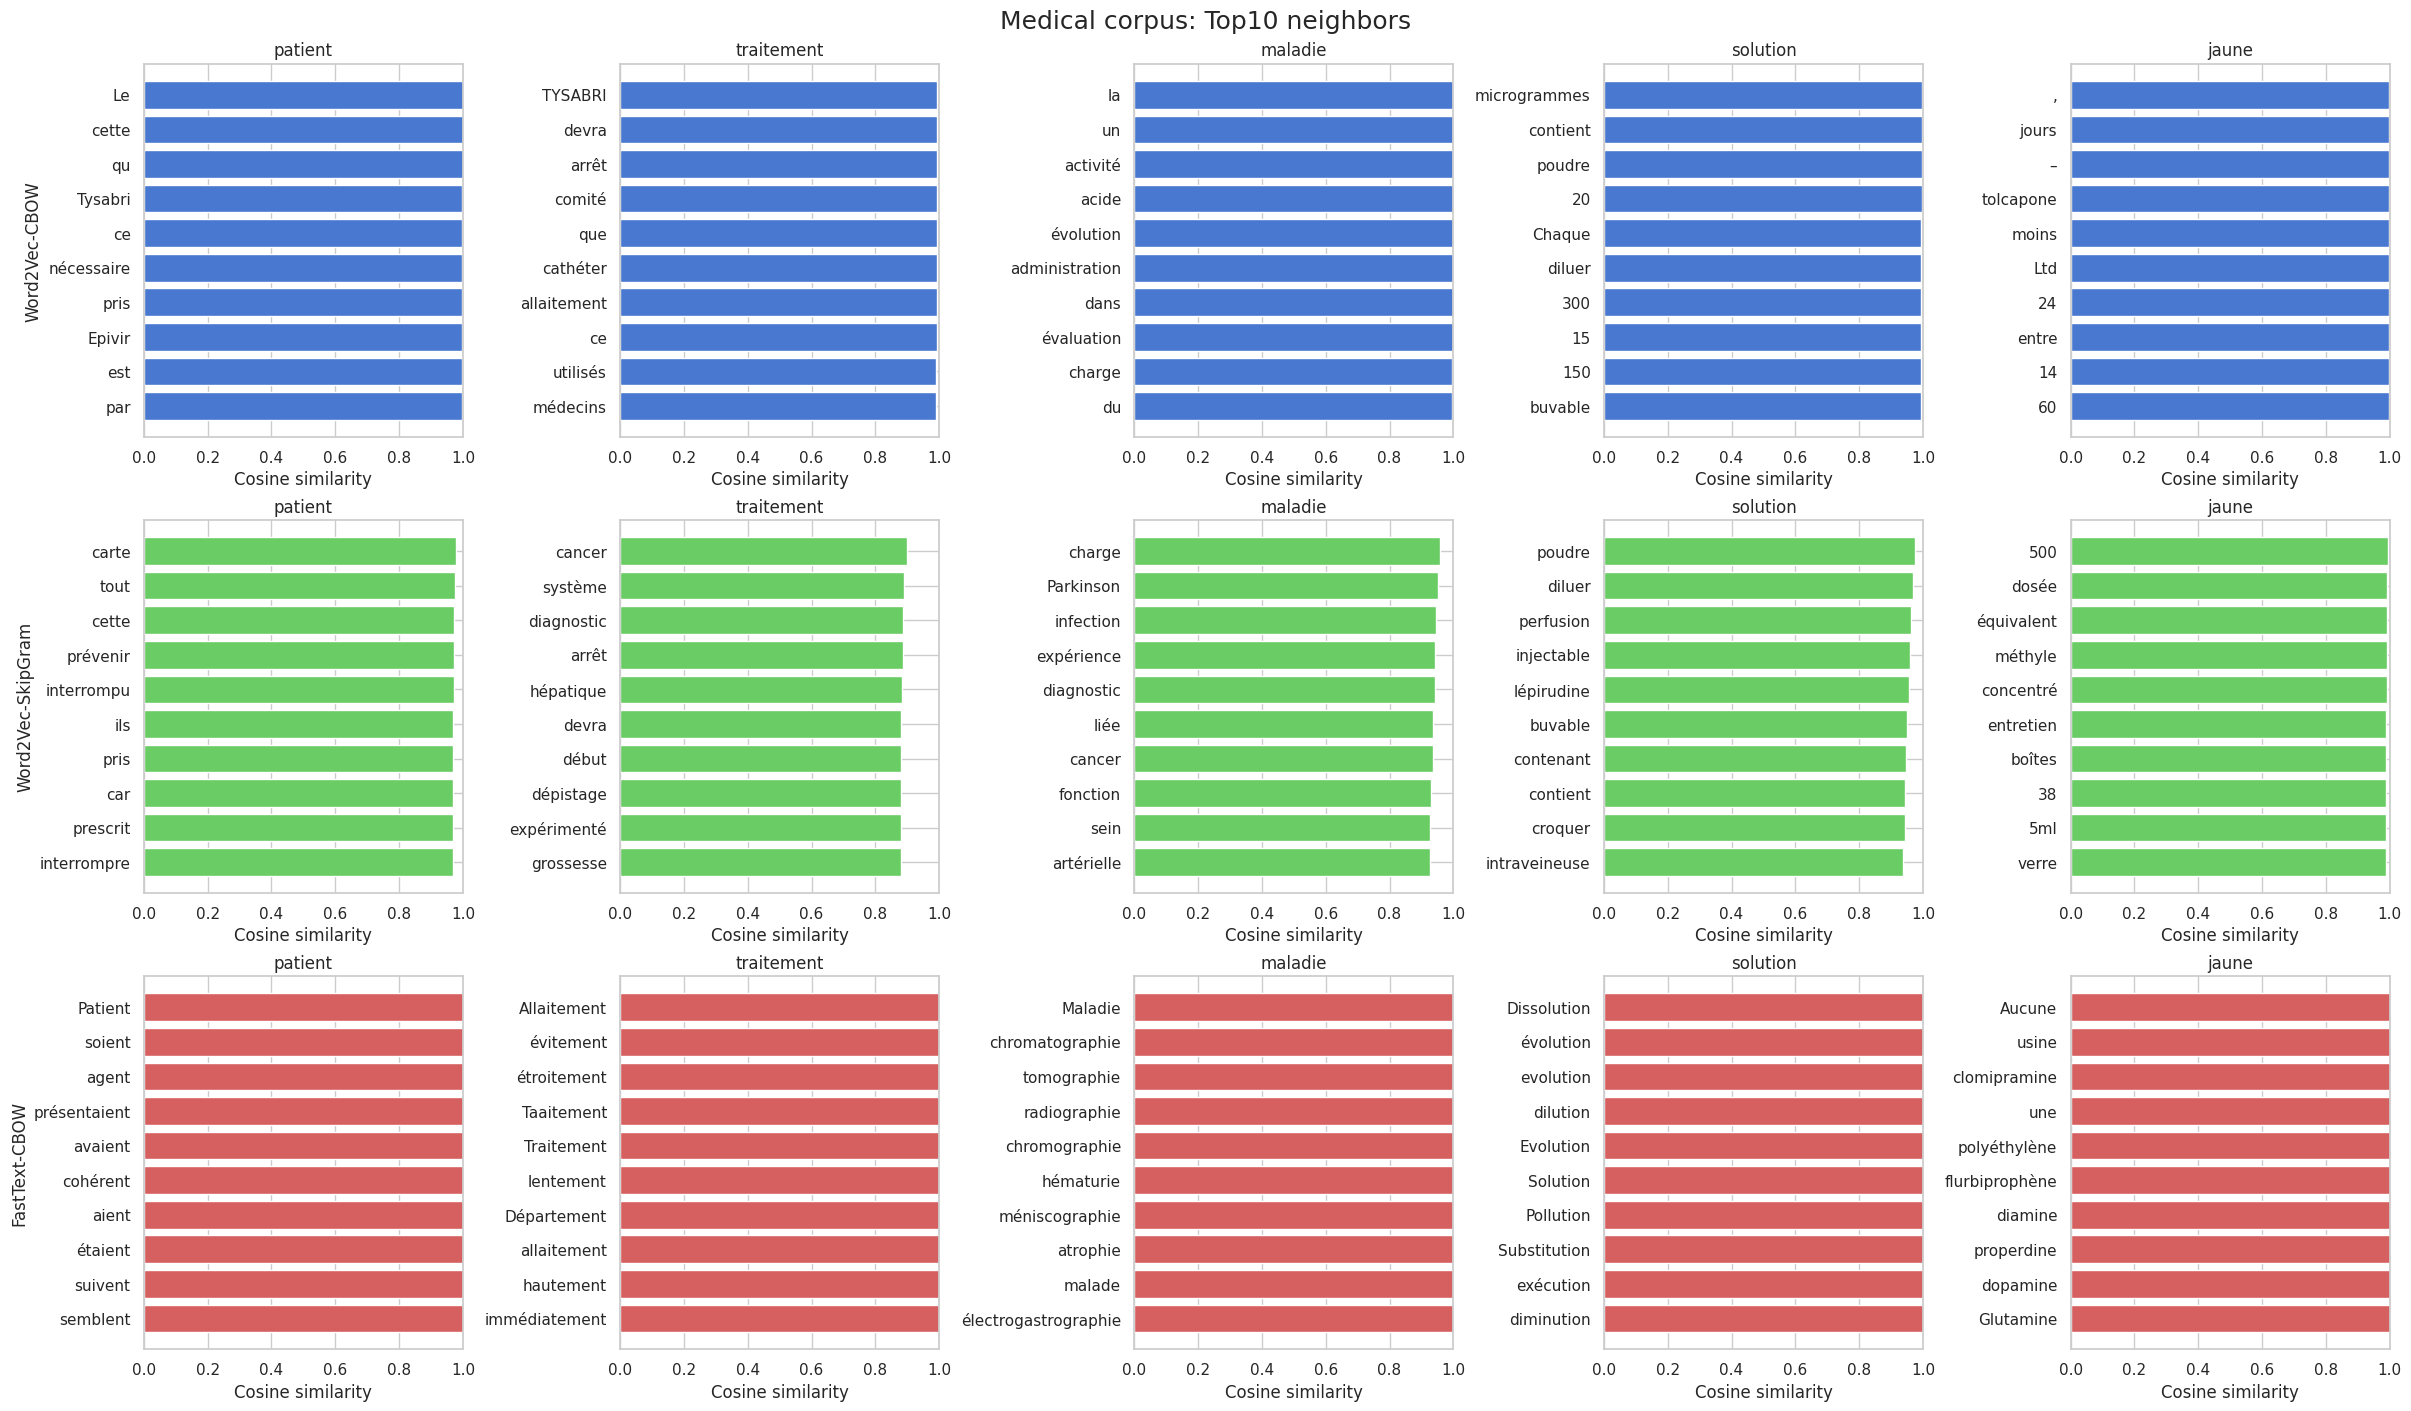

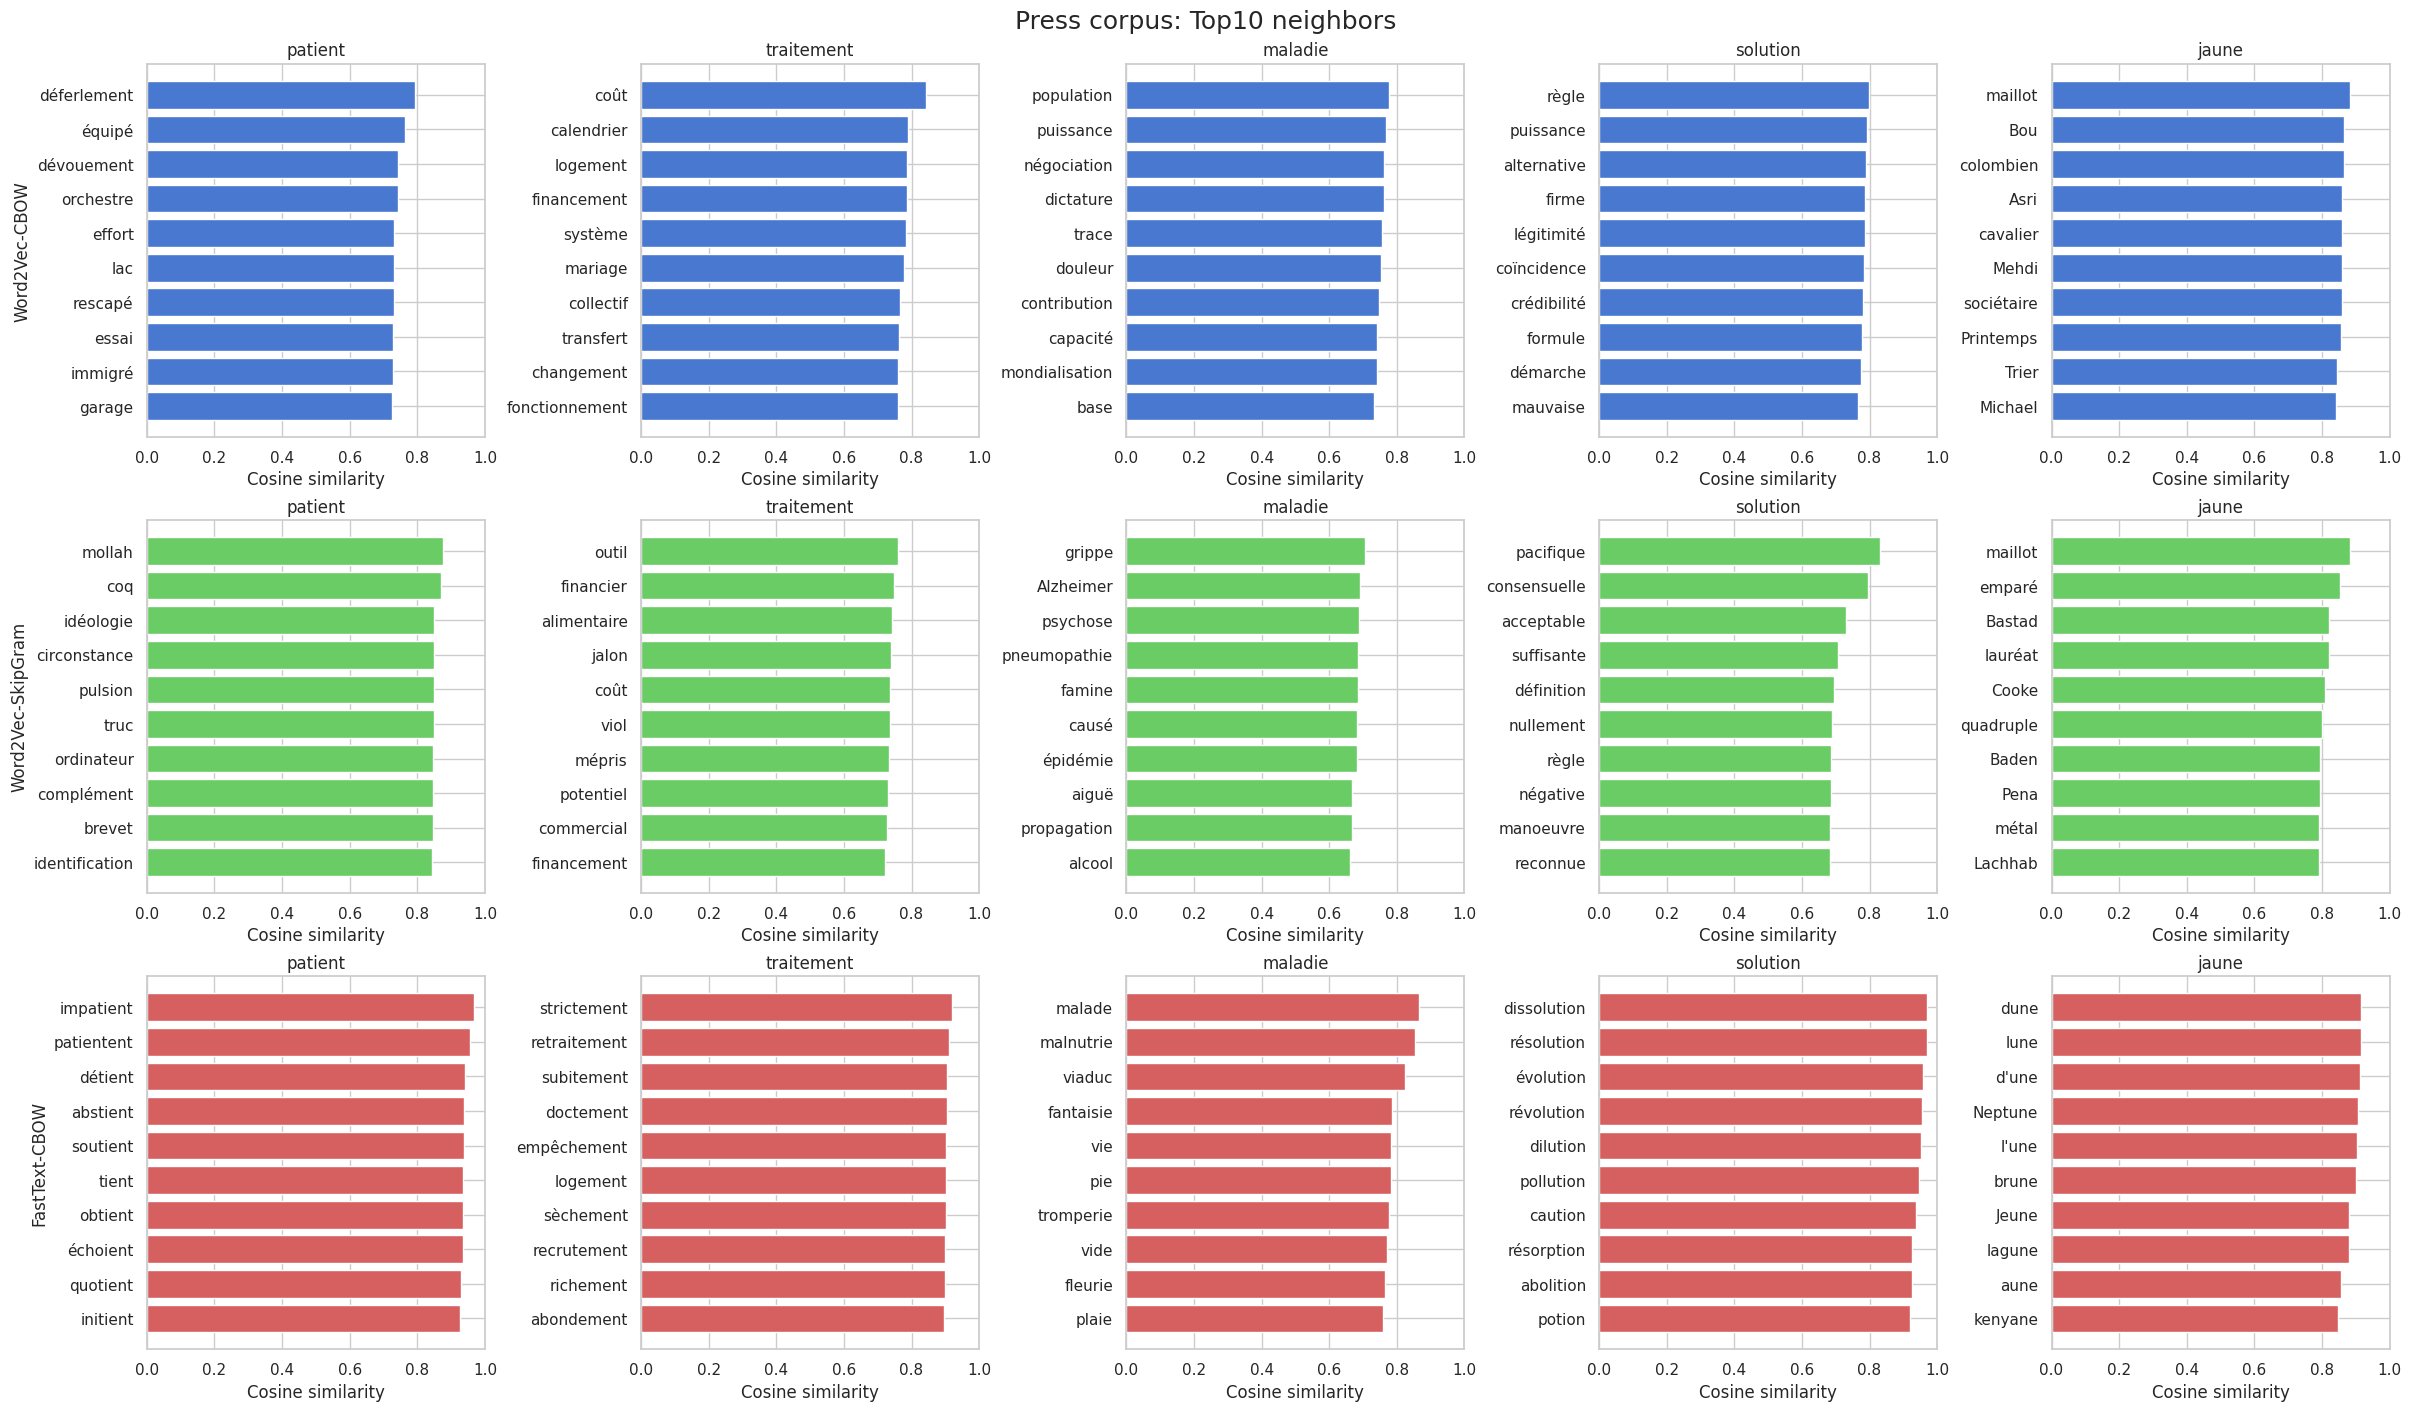

In [11]:
sns.set_theme(style='whitegrid', font='DejaVu Sans')

for corpus_name in DATA_PATHS:
    corpus_label = 'Medical' if corpus_name == 'Medical corpus' else 'Press'
    fig, axes = plt.subplots(3, 5, figsize=(24, 14), constrained_layout=True)
    fig.suptitle(f'{corpus_label} corpus: Top10 neighbors', fontsize=18)
    for row, model_name in enumerate(['Word2Vec-CBOW', 'Word2Vec-SkipGram', 'FastText-CBOW']):
        for col, target in enumerate(TARGET_WORDS):
            ax = axes[row, col]
            data = results_df[(results_df['Corpus'] == corpus_name) & (results_df['Model'] == model_name) & (results_df['Target'] == target)].sort_values('Cosine similarity')
            ax.barh(data['Neighbor'], data['Cosine similarity'], color=['#4878CF', '#6ACC65', '#D65F5F'][row])
            ax.set_title(target)
            ax.set_xlim(0, 1)
            ax.set_xlabel('Cosine similarity')
            ax.set_ylabel(model_name if col == 0 else '')
    fig.savefig(FIGURE_DIR / f"{corpus_name}_top10.png", dpi=160, bbox_inches='tight')
    plt.show()

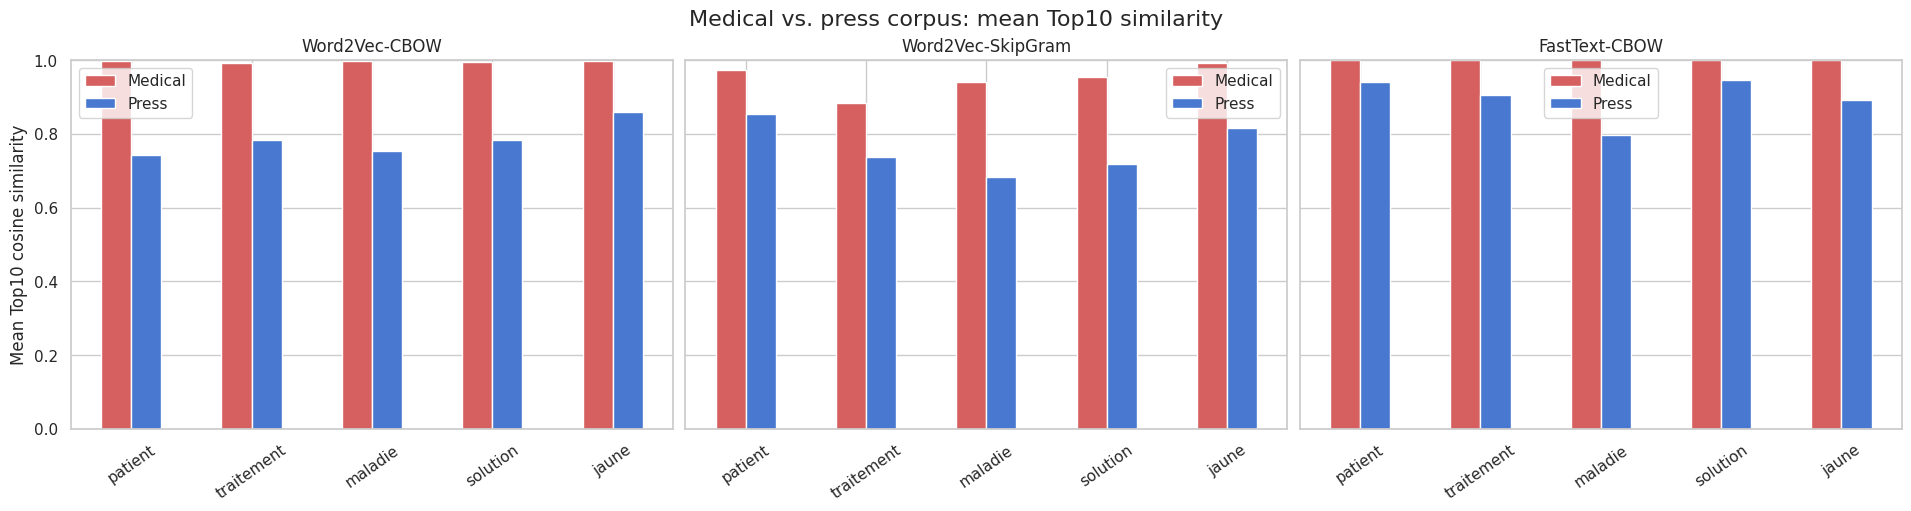

In [12]:
summary = (
    results_df.groupby(['Corpus', 'Model', 'Target'])['Cosine similarity']
    .agg(Top1='max', Top10_mean='mean')
    .reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(19, 5), sharey=True, constrained_layout=True)
for ax, model_name in zip(axes, ['Word2Vec-CBOW', 'Word2Vec-SkipGram', 'FastText-CBOW']):
    data = summary[summary['Model'] == model_name].pivot(index='Target', columns='Corpus', values='Top10_mean').reindex(TARGET_WORDS)
    data = data.rename(columns={'Medical corpus': 'Medical', 'Press corpus': 'Press'})
    data.columns.name = None
    data.plot(kind='bar', ax=ax, color=['#D65F5F', '#4878CF'])
    ax.set_title(model_name)
    ax.set_xlabel('')
    ax.set_ylabel('Mean Top10 cosine similarity' if ax is axes[0] else '')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=35)
fig.suptitle('Medical vs. press corpus: mean Top10 similarity', fontsize=16)
fig.savefig(FIGURE_DIR / 'corpus_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

## Analysis

### Model Differences Within Each Corpus

Word2Vec CBOW predicts a target word from its context and is usually more stable for frequent words. Skip-gram predicts context words from a target and often represents rare words better, so its neighbors and rankings differ from CBOW. In the medical corpus, words such as `patient`, `traitement`, and `maladie` tend to have domain-specific neighbors; the press corpus produces broader news-related associations.

FastText CBOW includes character n-grams. It can capture French morphology, shared affixes, and rare word forms, so its neighbors may reflect both semantic and subword similarity.

### Corpus Differences Within Each Model

The medical corpus is smaller but domain-focused, so neighbors are concentrated around diseases, treatments, patients, and drugs. The press corpus is larger and has a broader vocabulary, but its contexts are more varied. The comparison chart uses the mean similarity of each target word's Top10 neighbors.

`jaune` is relatively rare in the medical corpus, so its neighbors are more sensitive to limited context. In the press corpus, it may occur in descriptions of colors, people, or events. Frequency and the full Top10 list should therefore be considered together.

These similarities measure consistency within the training data, not dictionary accuracy. Results also depend on corpus size, word frequency, window size, initialization, and training epochs.